# 03 · ¿Mejoran los tiros al modelo? Una hipótesis que no se cumple

**Idea de partida.** Los goles son pocos (1,4 por equipo y partido) y muy afectados por la suerte: un balón al palo, una parada, un rebote. Un equipo puede jugar muy bien y no marcar. Los **tiros a puerta**, en cambio, son más abundantes (unos 5 por equipo y partido) y por eso parecen una señal **menos ruidosa** de lo bueno que es un equipo. La hipótesis:

> Si entrenamos el modelo con los goles esperados estimados a partir de los tiros, en lugar de con los goles reales, predecirá mejor.

**Spoiler:** no es así, y lo interesante es entender por qué. Un resultado negativo bien explicado es tan valioso como uno positivo, y evita confiar en una idea que "suena bien" sin haberla comprobado.

**Plan**
1. Convertir tiros en "goles esperados".
2. Probar la hipótesis con el mismo método de los cuadernos anteriores (periodo de ajuste 2012/13-2018/19).
3. Entender por qué falla.
4. Probar una variante: combinar los dos modelos.
5. Revisar si las probabilidades del modelo final están bien calibradas, de cara a la app.

*El examen final (2019/20 en adelante) no se usa para decidir nada en los apartados 1-4.*

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import nnls

import futbol as fb
import modelo as m

fb.estilo()
pd.set_option("display.width", 140)
%matplotlib inline

df = fb.cargar_laliga()
idx = m.indices_equipos(df)
cols_ps = ["pinnacle_cierre_local", "pinnacle_cierre_empate", "pinnacle_cierre_visitante"]
cols_prob = ["p_local", "p_empate", "p_visitante"]
AJUSTE = ("2012-08-01", "2019-06-30")
SEMIVIDA, RIDGE = 1.0, 2.0                      # los elegidos en el cuaderno 02

## 1. De los tiros a "goles esperados"

Cada partido trae los **tiros** de cada equipo y cuántos fueron **a puerta**. No todos los tiros valen lo mismo: uno a puerta acaba en gol bastante más a menudo que uno desviado. Para convertir tiros en goles esperados ajustamos una regresión sencilla con los partidos **anteriores a 2012/13** (así los coeficientes no usan información del periodo de evaluación):

$$\text{goles esperados} \approx c_1 \cdot \text{tiros a puerta} + c_2 \cdot \text{tiros fuera}$$

con $c_1, c_2 \geq 0$ (un tiro no puede restar goles esperados), que se calculan con mínimos cuadrados no negativos.

In [2]:
pre = df[df["fecha"] < "2012-08-01"]
X = np.vstack([
    np.column_stack([pre["tiros_puerta_local"], pre["tiros_local"] - pre["tiros_puerta_local"]]),
    np.column_stack([pre["tiros_puerta_visitante"], pre["tiros_visitante"] - pre["tiros_puerta_visitante"]]),
])
y = np.r_[pre["goles_local"], pre["goles_visitante"]]
(c_puerta, c_fuera), _ = nnls(X, y)
print(f"Goles esperados por cada tiro a puerta: {c_puerta:.3f}")
print(f"Goles esperados por cada tiro fuera:    {c_fuera:.3f}")
print(f"\nMedia de la liga en las temporadas completas: {df[df['temporada_completa']]['goles_local'].mean():.2f} goles y "
      f"{df[df['temporada_completa']]['tiros_puerta_local'].mean():.2f} tiros a puerta por partido del equipo local")

df["xg_local"] = c_puerta * df["tiros_puerta_local"] + c_fuera * (df["tiros_local"] - df["tiros_puerta_local"])
df["xg_visitante"] = c_puerta * df["tiros_puerta_visitante"] + c_fuera * (df["tiros_visitante"] - df["tiros_puerta_visitante"])

Goles esperados por cada tiro a puerta: 0.288
Goles esperados por cada tiro fuera:    0.000

Media de la liga en las temporadas completas: 1.53 goles y 4.88 tiros a puerta por partido del equipo local


Cada tiro a puerta equivale a unos **0,29 goles** y los tiros fuera **no aportan nada** (el coeficiente es cero). Así que, en la práctica, los goles esperados son `0,29 × tiros a puerta`.

## 2. La prueba

Mezclamos los dos tipos de "goles" con un peso $\alpha$:

$$\text{objetivo} = (1-\alpha)\cdot\text{goles reales} + \alpha\cdot\text{goles esperados por tiros}.$$

$\alpha = 0$ es el modelo del cuaderno 02 y $\alpha = 1$ el modelo basado solo en tiros. El modelo de Poisson se entrena igual con valores no enteros. Probamos varios $\alpha$ y varias semividas (porque con una señal menos ruidosa quizá convenga recordar más tiempo atrás), siempre con la validación temporal.

In [3]:
cuotas = df.set_index(["fecha", "local", "visitante"])[cols_ps]

def perdida(res):
    # Pérdida logarítmica sobre los partidos que tienen cuotas de Pinnacle (los mismos para todos los modelos)
    r = res.set_index(["fecha", "local", "visitante"]).join(cuotas).dropna(subset=cols_ps)
    return m.log_loss(r[cols_prob].to_numpy(), m.indice_resultado(r["resultado"]))

alfas = [0.0, 0.25, 0.5, 0.75, 1.0]
semividas = [1.0, 2.0, 4.0]
tabla = {}
for a in alfas:
    df["y_local"] = (1 - a) * df["goles_local"] + a * df["xg_local"]
    df["y_visitante"] = (1 - a) * df["goles_visitante"] + a * df["xg_visitante"]
    for sv in semividas:
        res = m.walk_forward(df, *AJUSTE, semividas_anios=sv, ridge=RIDGE, indice=idx,
                             col_local="y_local", col_visitante="y_visitante")
        tabla[(a, sv)] = perdida(res)

rejilla = pd.Series(tabla).unstack()
rejilla.index = [f"alfa = {a:g}" for a in rejilla.index]
rejilla.columns = [f"semivida {c:g} años" for c in rejilla.columns]
print("Pérdida logarítmica en el periodo de ajuste (menor es mejor):\n")
print(rejilla.round(4))

Pérdida logarítmica en el periodo de ajuste (menor es mejor):

             semivida 1 años  semivida 2 años  semivida 4 años
alfa = 0              0.9550           0.9558           0.9576
alfa = 0.25           0.9556           0.9570           0.9593
alfa = 0.5            0.9589           0.9606           0.9630
alfa = 0.75           0.9652           0.9667           0.9690
alfa = 1              0.9748           0.9756           0.9775


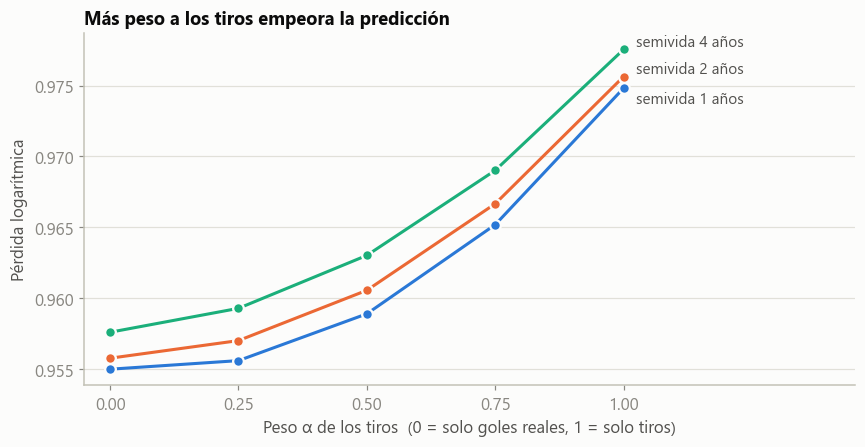

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = [fb.COLOR_LOCAL, fb.COLOR_VISITANTE, "#1baf7a"]
desplaz = {1.0: -7, 2.0: 5, 4.0: 5}                 # separa las etiquetas del extremo derecho
for sv, col in zip(semividas, colores):
    ax.plot(alfas, [tabla[(a, sv)] for a in alfas], "o-", color=col, markersize=7,
            markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
    ax.annotate(f"semivida {sv:g} años", (alfas[-1], tabla[(1.0, sv)]), xytext=(8, desplaz[sv]), textcoords="offset points",
                va="center", color=fb.TINTA_SECUNDARIA, fontsize=10)
ax.set_xlim(-0.05, 1.45)
ax.set_xticks(alfas)
ax.set_xlabel("Peso α de los tiros  (0 = solo goles reales, 1 = solo tiros)")
ax.set_ylabel("Pérdida logarítmica")
ax.set_title("Más peso a los tiros empeora la predicción")
plt.tight_layout()
plt.show()

**La hipótesis no se cumple: dar peso a los tiros empeora la predicción.** Con cualquier semivida, la mejor pérdida se obtiene con $\alpha = 0$ (solo goles reales): 0,9550 con semivida de 1 año. Con $\alpha = 0{,}25$ queda igual dentro del ruido (0,9556), y a partir de ahí empeora de forma continua hasta 0,9748 con solo tiros. Esa pérdida adicional (0,020) es del mismo tamaño que todo el hueco que nos separa de Pinnacle, así que no es un detalle menor.

Tampoco ayuda recordar más tiempo atrás: con semividas más largas todas las curvas son peores.

## 3. ¿Por qué falla?

Una explicación posible: **los equipos no son igual de buenos acabando las jugadas**. Si la "puntería" (goles por tiro a puerta) fuera puro azar, igual para todos, los tiros recogerían toda la información útil y serían mejores que los goles. Pero si es una **cualidad persistente de cada equipo** (delanteros de más calidad, mejores ocasiones), al quedarnos solo con los tiros la perdemos.

Lo comprobamos con datos: ¿la puntería de un equipo en una temporada se parece a la de la siguiente?

340 pares de temporadas consecutivas de un mismo equipo
Correlación de la puntería entre una temporada y la siguiente: 0.42
Correlación con los goles a favor de la temporada siguiente:  goles 0.84  |  tiros a puerta 0.80


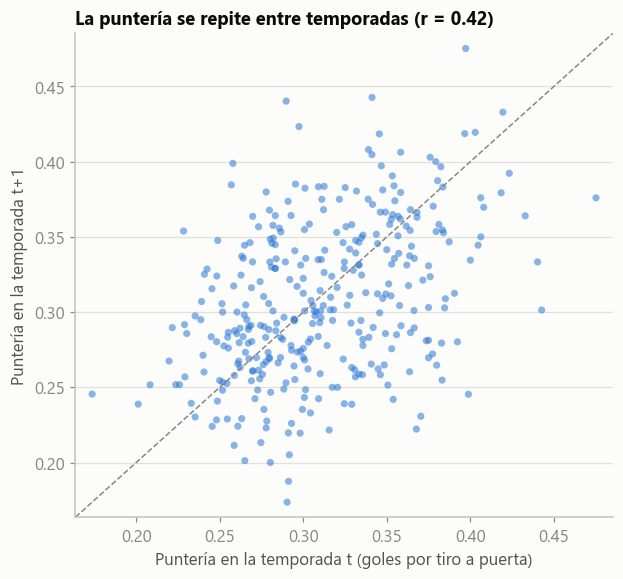


Media de la liga: 0.308 goles por tiro a puerta
Mejores finalizadores (≥ 8 temporadas):
              temporadas  punteria
equipo                           
Barcelona            21     0.378
Real Madrid          21     0.346
Ath Madrid           21     0.334
Valencia             21     0.333
Peores:
             temporadas  punteria
equipo                          
Malaga              11     0.274
Valladolid          10     0.268
Vallecano           11     0.259


In [5]:
c = df[df["temporada_completa"]]
loc = c.rename(columns={"local": "equipo", "goles_local": "gf", "goles_visitante": "gc",
                        "tiros_puerta_local": "stf", "tiros_puerta_visitante": "stc"})
vis = c.rename(columns={"visitante": "equipo", "goles_visitante": "gf", "goles_local": "gc",
                        "tiros_puerta_visitante": "stf", "tiros_puerta_local": "stc"})
cols = ["temporada", "equipo", "gf", "gc", "stf", "stc"]
t = pd.concat([loc[cols], vis[cols]]).groupby(["temporada", "equipo"]).sum().reset_index()   # una fila por equipo y temporada
t["punteria"] = t["gf"] / t["stf"]                      # goles marcados por tiro a puerta
t["anio"] = t["temporada"].str[:4].astype(int)

t = t.sort_values(["equipo", "anio"])
for col in ["punteria", "gf", "gc"]:
    t[col + "_sig"] = t.groupby("equipo")[col].shift(-1)
t["anio_sig"] = t.groupby("equipo")["anio"].shift(-1)
pares = t[t["anio_sig"] == t["anio"] + 1].dropna(subset=["punteria_sig"])      # temporadas consecutivas del mismo equipo

r_punt = np.corrcoef(pares["punteria"], pares["punteria_sig"])[0, 1]
print(f"{len(pares)} pares de temporadas consecutivas de un mismo equipo")
print(f"Correlación de la puntería entre una temporada y la siguiente: {r_punt:.2f}")
print(f"Correlación con los goles a favor de la temporada siguiente:  goles {np.corrcoef(pares['gf'], pares['gf_sig'])[0, 1]:.2f}"
      f"  |  tiros a puerta {np.corrcoef(pares['stf'], pares['gf_sig'])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(5.8, 5.4))
ax.scatter(pares["punteria"], pares["punteria_sig"], s=22, color=fb.COLOR_LOCAL, alpha=0.55, edgecolor="none")
lim = [pares[["punteria", "punteria_sig"]].min().min() - 0.01, pares[["punteria", "punteria_sig"]].max().max() + 0.01]
ax.plot(lim, lim, color=fb.TINTA_SUAVE, lw=1, ls="--")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Puntería en la temporada t (goles por tiro a puerta)")
ax.set_ylabel("Puntería en la temporada t+1")
ax.set_title(f"La puntería se repite entre temporadas (r = {r_punt:.2f})")
plt.tight_layout()
plt.show()

g = t.groupby("equipo").agg(temporadas=("temporada", "size"), gf=("gf", "sum"), stf=("stf", "sum"))
g["punteria"] = g["gf"] / g["stf"]
g = g[g["temporadas"] >= 8].sort_values("punteria", ascending=False)
media = t["gf"].sum() / t["stf"].sum()
print(f"\nMedia de la liga: {media:.3f} goles por tiro a puerta")
print("Mejores finalizadores (≥ 8 temporadas):\n", g[["temporadas", "punteria"]].head(4).round(3).to_string())
print("Peores:\n", g[["temporadas", "punteria"]].tail(3).round(3).to_string())

**La puntería no es puro azar: es una cualidad que se repite.** La correlación entre la puntería de un equipo en una temporada y en la siguiente es **0,42**, y hay equipos que acaban sistemáticamente mejor que la media de la liga (0,308 goles por tiro a puerta): Barcelona (0,378), Real Madrid (0,346), Atlético (0,334) y Valencia (0,333), frente a Málaga (0,274), Valladolid (0,268) o Rayo Vallecano (0,259).

Al entrenar solo con tiros suponemos que todos los equipos convierten cada tiro con la misma probabilidad, lo que infravalora a los mejores finalizadores y sobrevalora a los peores. Los datos lo confirman: **los goles de una temporada predicen los goles de la siguiente mejor (r = 0,84) que los tiros a puerta (r = 0,80)**. Los goles ya llevan incorporada la puntería; los tiros la ignoran. (Esa persistencia puede deberse a la calidad de los delanteros o a que se dispara desde mejores posiciones: con estos datos no se distingue.)

## 4. Una variante: combinar las predicciones

Aunque el modelo de tiros sea peor, podría recoger información **distinta** y sumar algo al combinarlo con el de goles. Probamos a promediar las probabilidades de los dos: $p = (1-w)\,p_{goles} + w\,p_{tiros}$. Con $w=0$ solo goles.

In [6]:
res_g = m.walk_forward(df, *AJUSTE, semividas_anios=SEMIVIDA, ridge=RIDGE, indice=idx)
res_t = m.walk_forward(df, *AJUSTE, semividas_anios=SEMIVIDA, ridge=RIDGE, indice=idx,
                       col_local="xg_local", col_visitante="xg_visitante")

a = res_g.set_index(["fecha", "local", "visitante"]).join(cuotas).dropna(subset=cols_ps)
b = res_t.set_index(["fecha", "local", "visitante"]).loc[a.index]
yy = m.indice_resultado(a["resultado"])

print(f"{'peso de los tiros w':>20}  pérdida")
for w in [0.0, 0.1, 0.2, 0.3, 0.5, 1.0]:
    p = (1 - w) * a[cols_prob].to_numpy() + w * b[cols_prob].to_numpy()
    print(f"{w:>20.1f}  {m.log_loss(p, yy):.4f}")

 peso de los tiros w  pérdida
                 0.0  0.9550
                 0.1  0.9552
                 0.2  0.9558
                 0.3  0.9568
                 0.5  0.9601
                 1.0  0.9748


**Combinar tampoco ayuda.** La mejor pérdida es con $w = 0$ (solo goles, 0,9550); cualquier peso para los tiros empeora: 0,9552 con 0,1, 0,9568 con 0,3 y 0,9748 con 1. Los tiros no aportan información que los goles no tengan ya, ni siquiera al sumarla a la de los goles.

## 5. Antes de la app: ¿están calibradas las probabilidades del modelo?

Como el modelo final sigue siendo el del cuaderno 02 (goles reales, semivida de 1 año, ridge 2), comprobamos su **calibración** sobre el examen (2019/20 en adelante), igual que hicimos con Pinnacle: de todos los resultados a los que el modelo daba, por ejemplo, un 30 % de probabilidad, ¿ocurrió el 30 %? Es un diagnóstico, no se usa para decidir nada.

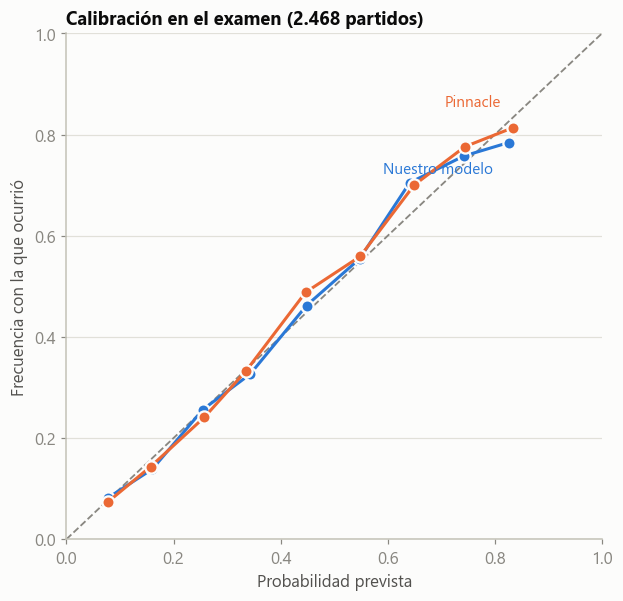

       prob. modelo  real (modelo)     n  prob. Pinnacle  real (Pinnacle)
tramo                                                                    
0             0.078          0.082   170           0.077            0.074
1             0.160          0.138   910           0.157            0.144
2             0.255          0.256  2952           0.258            0.241
3             0.343          0.327  1356           0.336            0.333
4             0.448          0.462   896           0.447            0.488
5             0.548          0.555   586           0.549            0.559
6             0.641          0.705   322           0.649            0.700
7             0.742          0.758   161           0.744            0.776
8             0.826          0.784    51           0.834            0.814


In [7]:
res_final = m.walk_forward(df, "2019-08-01", "2026-12-31", semividas_anios=SEMIVIDA, ridge=RIDGE, indice=idx)
r = res_final.set_index(["fecha", "local", "visitante"]).join(cuotas).dropna(subset=cols_ps)
pm = r[cols_prob].to_numpy()
pp, _ = fb.probabilidades_implicitas(*(r[c] for c in cols_ps))
yv = m.indice_resultado(r["resultado"])
ocurrio = np.zeros_like(pm); ocurrio[np.arange(len(yv)), yv] = 1

def calibracion(probs, real, tramos=np.arange(0, 1.0001, 0.1)):
    cubo = np.clip(np.digitize(probs.ravel(), tramos) - 1, 0, len(tramos) - 2)
    d = pd.DataFrame({"p": probs.ravel(), "real": real.ravel(), "tramo": cubo}).groupby("tramo").agg(
        prob_media=("p", "mean"), frecuencia=("real", "mean"), n=("real", "size"))
    return d

cal_m, cal_p = calibracion(pm, ocurrio), calibracion(pp, ocurrio)

fig, ax = plt.subplots(figsize=(5.8, 5.6))
ax.plot([0, 1], [0, 1], color=fb.TINTA_SUAVE, lw=1.2, ls="--")
ax.plot(cal_m["prob_media"], cal_m["frecuencia"], "o-", color=fb.COLOR_LOCAL, markersize=8, markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
ax.plot(cal_p["prob_media"], cal_p["frecuencia"], "o-", color=fb.COLOR_VISITANTE, markersize=8, markeredgecolor=fb.SUPERFICIE, markeredgewidth=1.5)
ax.annotate("Nuestro modelo", (cal_m["prob_media"].iloc[-1], cal_m["frecuencia"].iloc[-1]), xytext=(-10, -20),
            textcoords="offset points", color=fb.COLOR_LOCAL, fontsize=10, ha="right")
ax.annotate("Pinnacle", (cal_p["prob_media"].iloc[-1], cal_p["frecuencia"].iloc[-1]), xytext=(-8, 14),
            textcoords="offset points", color=fb.COLOR_VISITANTE, fontsize=10, ha="right")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Probabilidad prevista")
ax.set_ylabel("Frecuencia con la que ocurrió")
ax.set_title(f"Calibración en el examen ({fb.miles(len(r))} partidos)")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"prob. modelo": cal_m["prob_media"], "real (modelo)": cal_m["frecuencia"], "n": cal_m["n"],
                    "prob. Pinnacle": cal_p["prob_media"], "real (Pinnacle)": cal_p["frecuencia"]}).round(3))

**Las probabilidades del modelo son fiables y se parecen mucho a las de Pinnacle.** Cuando el modelo dice un 25 % (el tramo con más partidos, 2.952) ocurre el 25,6 %; cuando dice un 55 %, ocurre el 55,5 %. Se aprecian pequeñas desviaciones:

* En los favoritos moderados (≈ 64 %) ocurrió un 70,5 %: los favoritos ganan algo más de lo previsto. Pinnacle muestra la misma desviación (65 % → 70 %), así que parece una característica de los datos y no un fallo del modelo.
* En el tramo más alto (83 %) ocurrió el 78 %, pero son solo 51 partidos: no hay que sacar conclusiones fuertes.

Para la app, esto significa que se pueden leer las probabilidades como lo que son, sin retoques.

## 6. Conclusiones

* **Los tiros no mejoran el modelo; lo empeoran.** Cuanto más peso se da a los goles esperados por tiros, peor es la predicción (de 0,9550 con solo goles a 0,9748 con solo tiros). Combinar los dos modelos tampoco ayuda.
* **La razón es la puntería.** Los equipos no convierten igual sus tiros, y esa diferencia **persiste** de una temporada a otra (r = 0,42). Los goles ya contienen esa información; los tiros la tiran.
* **El modelo final no cambia:** Poisson con ataque y defensa por equipo y ventaja local, entrenado con goles reales, semivida de 1 año y ridge = 2. Cierra el 82 % del hueco hasta Pinnacle y sus probabilidades están bien calibradas.

**Lección de método.** Una idea plausible ("los tiros son menos ruidosos que los goles") se comprueba con el mismo procedimiento honesto (validación temporal y un periodo para decidir) y, si falla, se entiende por qué antes de descartarla. Un resultado negativo bien diagnosticado es información útil y evita complicar el modelo sin motivo.

**Siguiente paso.** Construir la **app**: elegir un partido (local y visitante) y ver las probabilidades de victoria, empate y derrota, los marcadores más probables y el ataque y la defensa de cada equipo, con el modelo reajustado con todos los partidos hasta hoy.